<a href="https://colab.research.google.com/github/mahekparekhbba2025-prog/Wordify/blob/main/SCM_Practical_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1> Problem Statement : Inaccurate demand forecasting leads to stockouts (lost revenue and degraded customer service) or excess inventory (high holding costs and tied-up working capital).

In [3]:
#STEP 1 - Problem definition and synthetic dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set seed for reproducibility
np.random.seed(42)

# Generate 104 weeks (2 years) of weekly data for 10 FMCG SKUs = 1,040 total rows
dates = pd.date_range(start="2024-01-01", periods=104, freq="W-MON")
products = [
    {"id": "P001", "name": "Potato Chips 100g", "base": 200, "price": 20.0, "lead_time": 5},
    {"id": "P002", "name": "Biscuits 200g", "base": 170, "price": 35.0, "lead_time": 7},
    {"id": "P003", "name": "Instant Noodles Pack", "base": 250, "price": 15.0, "lead_time": 4},
    {"id": "P004", "name": "Namkeen 200g", "base": 130, "price": 50.0, "lead_time": 6},
    {"id": "P005", "name": "Fruit Juice 1L", "base": 110, "price": 80.0, "lead_time": 8},
    {"id": "P006", "name": "Hand Wash 200ml", "base": 140, "price": 90.0, "lead_time": 7},
    {"id": "P007", "name": "Chocolate Bar 50g", "base": 300, "price": 25.0, "lead_time": 3},
    {"id": "P008", "name": "Detergent Powder 1kg", "base": 180, "price": 120.0, "lead_time": 10},
    {"id": "P009", "name": "Green Tea 25 Bags", "base": 90, "price": 150.0, "lead_time": 6},
    {"id": "P010", "name": "Toothpaste 150g", "base": 220, "price": 65.0, "lead_time": 5}
]

raw_data = []
for p in products:
    for i, d in enumerate(dates):
        trend = i * 0.12
        seasonality = 1.25 if d.month in [6, 7, 11, 12] else 1.0
        promo = 1 if np.random.rand() < 0.15 else 0
        promo_impact = 1.30 if promo == 1 else 1.0
        noise = np.random.normal(0, 12)

        qty = int(max(0, (p["base"] + trend) * seasonality * promo_impact + noise))
        stock = int(qty * np.random.uniform(0.85, 1.35))

        raw_data.append({
            "Date": d,
            "Product_ID": p["id"],
            "Product_Name": p["name"],
            "Quantity_Sold": qty,
            "Unit_Price": round(p["price"] * np.random.uniform(0.98, 1.02), 2),
            "Promotion": promo,
            "Stock_Available": stock,
            "Lead_Time_Days": p["lead_time"]
        })

df_raw = pd.DataFrame(raw_data)
raw_path = "/content/demand_forecasting_synthetic_raw_dataset.csv"
df_raw.to_csv(raw_path, index=False)
print(f"✅ Raw Dataset Created: {len(df_raw)} rows across {df_raw['Product_ID'].nunique()} products.")
display(df_raw.head())

✅ Raw Dataset Created: 1040 rows across 10 products.


,Date,Product_ID,Product_Name,Quantity_Sold,Unit_Price,Promotion,Stock_Available,Lead_Time_Days
0,2024-01-01,P001,Potato Chips 100g,186,19.65,0,172,5
1,2024-01-08,P001,Potato Chips 100g,203,20.17,0,233,5
2,2024-01-15,P001,Potato Chips 100g,253,19.84,1,238,5
3,2024-01-22,P001,Potato Chips 100g,194,19.83,0,206,5
4,2024-01-29,P001,Potato Chips 100g,195,19.96,0,201,5


In [4]:
#STEP 2 - Data Pre-processing & Data Quality Log
cleaning_log = []
def log_action(action, count, decision):
    cleaning_log.append({"Action": action, "Count": int(count), "Decision": decision})

df = df_raw.copy()
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
log_action("Invalid date check", df["Date"].isna().sum(), "Excluded unusable dates.")

# Duplicate check
dups = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
log_action("Exact duplicates removed", dups, "Removed duplicate records.")

# Range checks
invalid_mask = (
    (df["Quantity_Sold"] < 0) |
    (df["Unit_Price"] <= 0) |
    (df["Stock_Available"] < 0) |
    (df["Lead_Time_Days"] < 0) |
    (~df["Promotion"].isin([0, 1]))
)
log_action("Invalid range check", int(invalid_mask.sum()), "Removed invalid numerical values.")
df = df.loc[~invalid_mask].copy()

# Flag Outliers via IQR
df["Quantity_Sold_Outlier"] = False
outlier_total = 0
for pid, idx in df.groupby("Product_ID").groups.items():
    vals = df.loc[idx, "Quantity_Sold"]
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    iqr = q3 - q1
    flag = (vals < (q1 - 1.5 * iqr)) | (vals > (q3 + 1.5 * iqr))
    df.loc[idx, "Quantity_Sold_Outlier"] = flag
    outlier_total += int(flag.sum())

log_action("Outliers flagged", outlier_total, "IQR rule applied per product; retained for demand spikes.")

# Fill weekly date gaps
complete_parts = []
inserted_total = 0
for pid, part in df.groupby("Product_ID"):
    part = part.sort_values("Date").copy()
    pname = part["Product_Name"].iloc[0]
    full_dates = pd.date_range(part["Date"].min(), part["Date"].max(), freq="W-MON")
    part = part.set_index("Date").reindex(full_dates)
    part.index.name = "Date"
    part["Product_ID"] = pid
    part["Product_Name"] = pname
    inserted = part["Quantity_Sold"].isna()
    inserted_total += int(inserted.sum())
    part["Inserted_Date_Row"] = inserted
    part["Quantity_Sold"] = part["Quantity_Sold"].fillna(0)
    for col in ["Unit_Price", "Stock_Available", "Lead_Time_Days"]:
        part[col] = part[col].ffill().bfill()
    part["Promotion"] = part["Promotion"].fillna(0)
    part["Quantity_Sold_Outlier"] = part["Quantity_Sold_Outlier"].fillna(False)
    complete_parts.append(part.reset_index())

cleaned_df = pd.concat(complete_parts, ignore_index=True)
cleaned_df = cleaned_df.sort_values(["Product_ID", "Date"]).reset_index(drop=True)
log_action("Weekly date gaps filled", inserted_total, "Inserted missing weeks with zero sales.")

cleaned_path = "/content/demand_forecasting_cleaned_dataset.csv"
log_path = "/content/step5_cleaning_log.csv"
cleaned_df.to_csv(cleaned_path, index=False)
pd.DataFrame(cleaning_log).to_csv(log_path, index=False)

print("✅ Data Pre-processing Completed.")
display(pd.DataFrame(cleaning_log))

✅ Data Pre-processing Completed.


,Action,Count,Decision
0,Invalid date check,0,Excluded unusable dates.
1,Exact duplicates removed,0,Removed duplicate records.
2,Invalid range check,0,Removed invalid numerical values.
3,Outliers flagged,14,IQR rule applied per product; retained for dem...
4,Weekly date gaps filled,0,Inserted missing weeks with zero sales.


In [17]:
#STEP 3 - Feature Engineering
#Generates lag variables, rolling statistics (4-week and 8-week means), and promotion/price change indicators.
fe_df = cleaned_df.copy()
fe_df["Month"] = fe_df["Date"].dt.month
fe_df["Weekday"] = fe_df["Date"].dt.weekday
fe_df["Holiday_Flag"] = 0

for lag in [1, 2, 4]:
    fe_df[f"Lag_{lag}"] = fe_df.groupby("Product_ID")["Quantity_Sold"].shift(lag)

for window in [4, 8]:
    fe_df[f"Rolling_Avg_{window}"] = fe_df.groupby("Product_ID")["Quantity_Sold"].transform(lambda s: s.shift(1).rolling(window).mean())

fe_df["Promotion_Flag"] = fe_df["Promotion"].astype(int)
prev_price = fe_df.groupby("Product_ID")["Unit_Price"].shift(1)
fe_df["Price_Change_Pct"] = ((fe_df["Unit_Price"] - prev_price) / prev_price.replace(0, np.nan)).fillna(0) * 100
fe_df["Price_Change_Flag"] = (fe_df["Unit_Price"] > prev_price).astype(int)

model_ready_path = "/content/demand_forecasting_model_ready_dataset.csv"
fe_df.to_csv(model_ready_path, index=False)
print(f"✅ Feature Engineering Completed. Shape: {fe_df.shape}")


✅ Feature Engineering Completed. Shape: (1040, 21)


/tmp/ipykernel_3082/3819944010.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cv_df.sort_values("CV_Percentage"), x="CV_Percentage", y="Product_Name", palette="Blues_r")


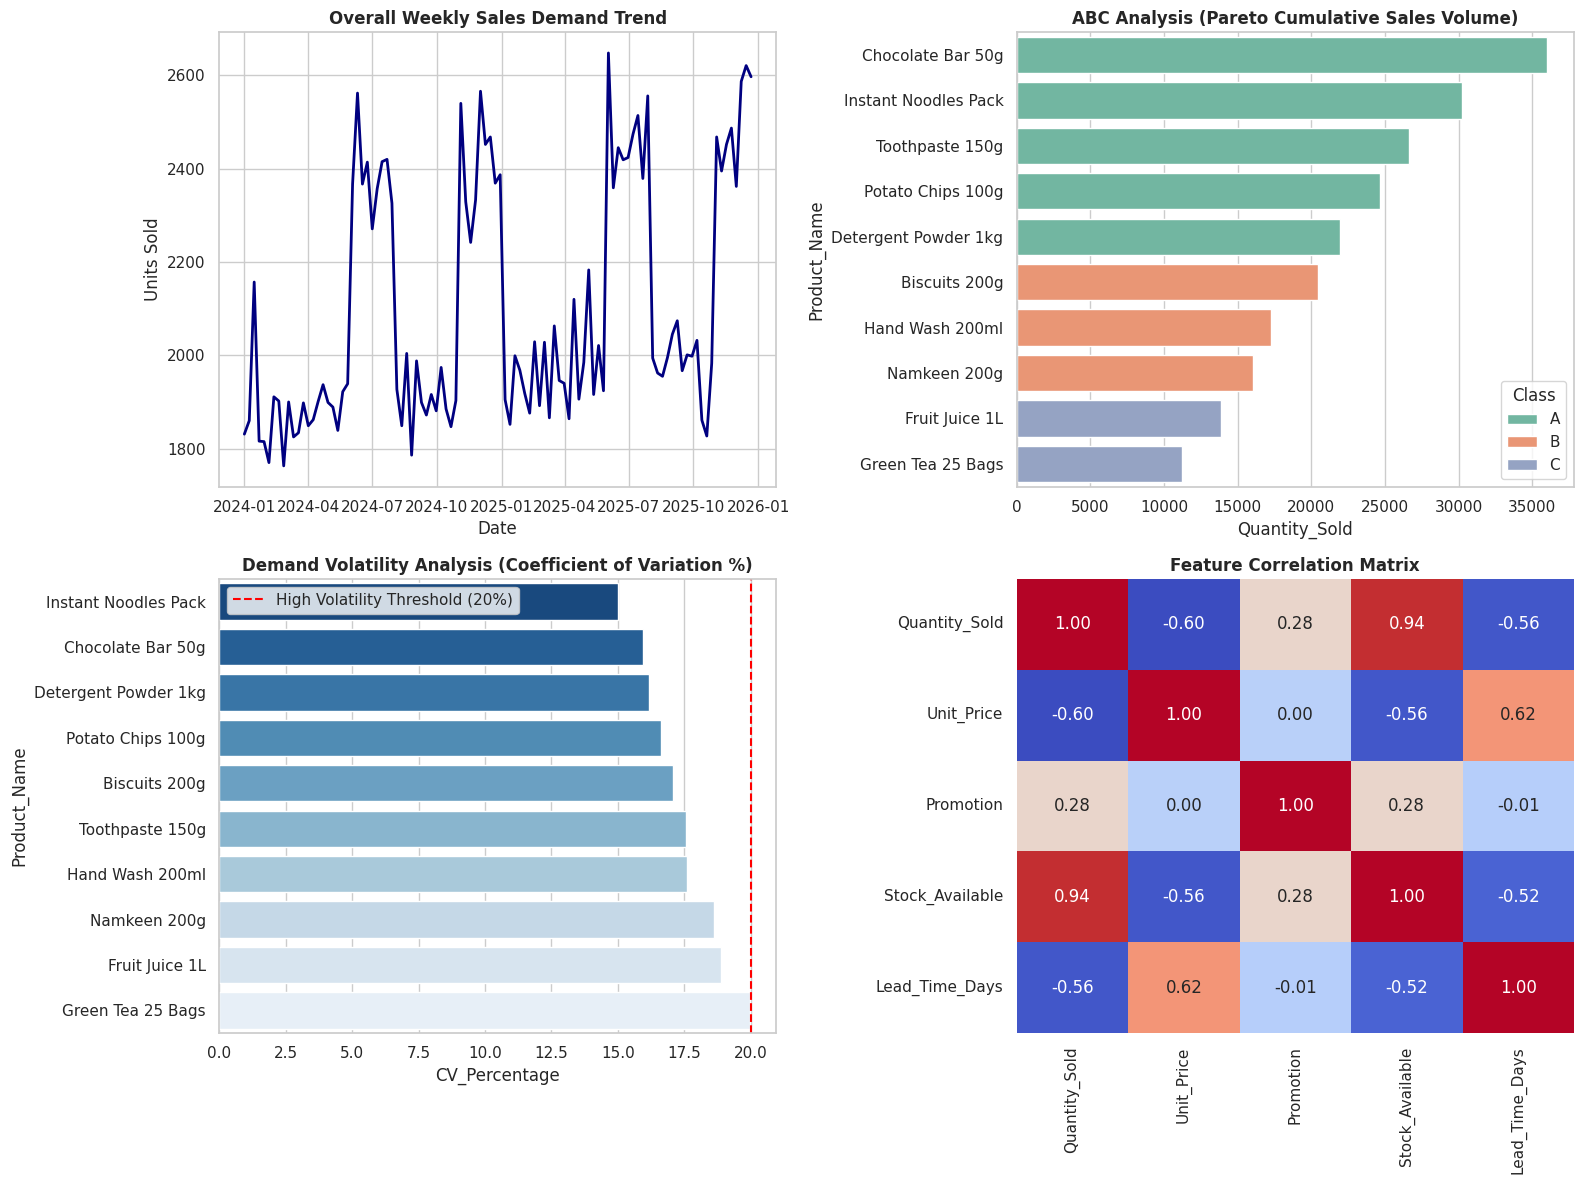

In [26]:
#STEP 4 - Exploratory Data Analysis (EDA) & Visualizations
#Plots Overall Demand Trends, Monthly Seasonality, ABC Revenue Categorization, XYZ Demand Volatility and Feature Correlation Heatmap.
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Weekly Demand Trend
plt.subplot(2, 2, 1)
weekly_total = fe_df.groupby("Date")["Quantity_Sold"].sum()
plt.plot(weekly_total.index, weekly_total.values, color="navy", linewidth=2)
plt.title("Overall Weekly Sales Demand Trend", fontsize=12, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Units Sold")

# 2. ABC Classification
plt.subplot(2, 2, 2)
abc = fe_df.groupby("Product_Name")["Quantity_Sold"].sum().reset_index().sort_values("Quantity_Sold", ascending=False)
abc["Cumulative_Pct"] = (abc["Quantity_Sold"].cumsum() / abc["Quantity_Sold"].sum()) * 100
abc["Class"] = np.select([abc["Cumulative_Pct"] <= 70, abc["Cumulative_Pct"] <= 90], ["A", "B"], default="C")
sns.barplot(data=abc, x="Quantity_Sold", y="Product_Name", hue="Class", palette="Set2", dodge=False)
plt.title("ABC Analysis (Pareto Cumulative Sales Volume)", fontsize=12, fontweight="bold")

# 3. XYZ Demand Volatility (CV%)
plt.subplot(2, 2, 3)
cv_df = fe_df.groupby("Product_Name")["Quantity_Sold"].agg(["mean", "std"]).reset_index()
cv_df["CV_Percentage"] = (cv_df["std"] / cv_df["mean"]) * 100
sns.barplot(data=cv_df.sort_values("CV_Percentage"), x="CV_Percentage", y="Product_Name", palette="Blues_r")
plt.axvline(20, color="red", linestyle="--", label="High Volatility Threshold (20%)")
plt.title("Demand Volatility Analysis (Coefficient of Variation %)", fontsize=12, fontweight="bold")
plt.legend()

# 4. Correlation Heatmap
plt.subplot(2, 2, 4)
corr_cols = ["Quantity_Sold", "Unit_Price", "Promotion", "Stock_Available", "Lead_Time_Days"]
sns.heatmap(fe_df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", cbar=False)
plt.title("Feature Correlation Matrix", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3082/2372834998.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_scores, x="Model", y="RMSE", palette="viridis")


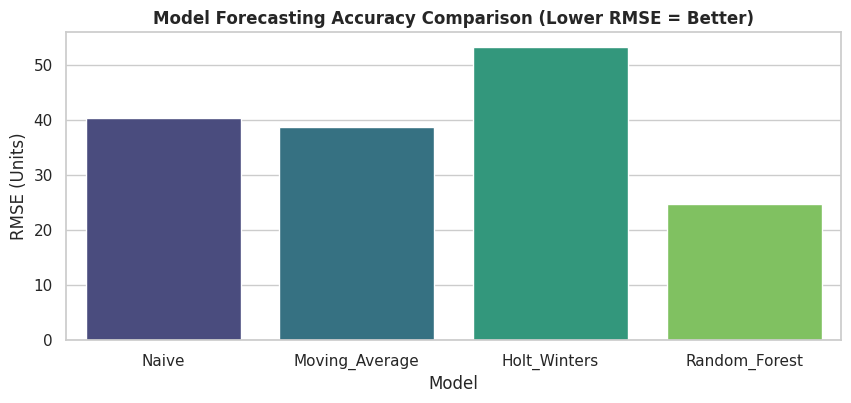

,Model,MAE,RMSE,MAPE (%)
0,Naive,28.157,40.339,13.64
1,Moving_Average,28.719,38.704,13.20
2,Holt_Winters,44.885,53.231,23.40
3,Random_Forest,18.972,24.766,9.16


In [19]:
#STEP 5 - Forecasting Model Building, Benchmarking & Evaluation
#Executes an 80:20 chronological train-test split to train and evaluate Naive, Moving Average, Holt-Winters, and Random Forest models across MAE, RMSE, and MAPE.
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_results = []
for pid, group in fe_df.groupby("Product_ID"):
    group = group.sort_values("Date").reset_index(drop=True)
    split = int(len(group) * 0.8)
    train, test = group.iloc[:split].copy(), group.iloc[split:].copy()

    # 1. Naive
    test_naive = test["Lag_1"].fillna(train["Quantity_Sold"].iloc[-1]).values
    # 2. Moving Average
    test_ma = test["Rolling_Avg_4"].fillna(train["Quantity_Sold"].tail(4).mean()).values

    # 3. Holt-Winters
    try:
        hw = ExponentialSmoothing(train["Quantity_Sold"].astype(float), trend="add", seasonal=None).fit()
        hw_pred = hw.forecast(len(test)).values
    except:
        hw_pred = np.full(len(test), train["Quantity_Sold"].iloc[-1])

    # 4. Random Forest
    features = ["Lag_1", "Lag_2", "Lag_4", "Rolling_Avg_4", "Rolling_Avg_8", "Month", "Promotion_Flag", "Price_Change_Pct"]
    X_train = train[features].replace([np.inf, -np.inf], np.nan).fillna(0)
    X_test = test[features].replace([np.inf, -np.inf], np.nan).fillna(0)

    rf = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
    rf.fit(X_train, train["Quantity_Sold"])
    rf_pred = rf.predict(X_test)

    for i, (_, row) in enumerate(test.iterrows()):
        forecast_results.append({
            "Date": row["Date"],
            "Product_ID": pid,
            "Actual": row["Quantity_Sold"],
            "Naive": max(0, test_naive[i]),
            "Moving_Average": max(0, test_ma[i]),
            "Holt_Winters": max(0, hw_pred[i]),
            "Random_Forest": max(0, rf_pred[i])
        })

df_forecasts = pd.DataFrame(forecast_results)
df_forecasts.to_csv("/content/step9_test_forecasts.csv", index=False)

# Model Metric Evaluation
scores = []
for model_name in ["Naive", "Moving_Average", "Holt_Winters", "Random_Forest"]:
    actual = df_forecasts["Actual"]
    pred = df_forecasts[model_name]
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mape = np.mean(np.abs((actual - pred) / np.where(actual == 0, 1, actual))) * 100
    scores.append({"Model": model_name, "MAE": round(mae, 3), "RMSE": round(rmse, 3), "MAPE (%)": round(mape, 2)})

df_scores = pd.DataFrame(scores)
df_scores.to_csv("/content/step10_model_comparison.csv", index=False)

# Plot Model Comparison
plt.figure(figsize=(10, 4))
sns.barplot(data=df_scores, x="Model", y="RMSE", palette="viridis")
plt.title("Model Forecasting Accuracy Comparison (Lower RMSE = Better)", fontsize=12, fontweight="bold")
plt.ylabel("RMSE (Units)")
plt.show()

display(df_scores)

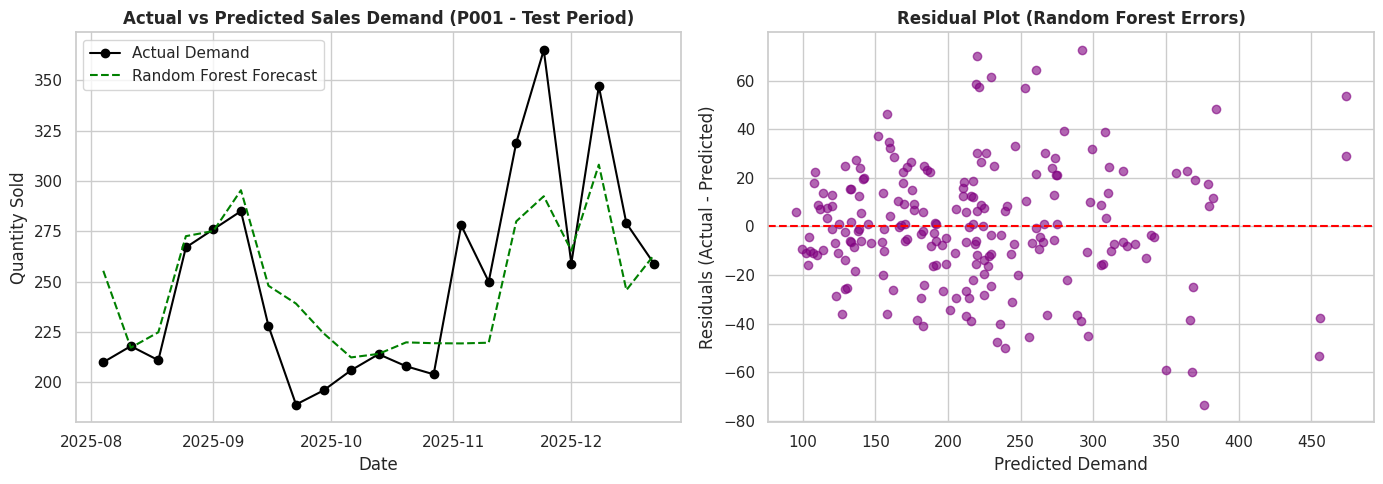

In [20]:
#STEP 6 - Actual vs. Predicted Demand & Residual Analysis Plot
#Displays model predictions against ground truth and plots residual distribution to verify model unbiasedness.
plt.figure(figsize=(14, 5))

# Actual vs Predicted Plot
plt.subplot(1, 2, 1)
sample_product = df_forecasts[df_forecasts["Product_ID"] == "P001"]
plt.plot(sample_product["Date"], sample_product["Actual"], label="Actual Demand", marker="o", color="black")
plt.plot(sample_product["Date"], sample_product["Random_Forest"], label="Random Forest Forecast", linestyle="--", color="green")
plt.title("Actual vs Predicted Sales Demand (P001 - Test Period)", fontsize=12, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.legend()

# Residual Plot
plt.subplot(1, 2, 2)
residuals = df_forecasts["Actual"] - df_forecasts["Random_Forest"]
plt.scatter(df_forecasts["Random_Forest"], residuals, alpha=0.6, color="purple")
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Plot (Random Forest Errors)", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Demand")
plt.ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [21]:
#STEP 7 - 4-Week Future Demand Forecasting & Uncertainty Interval
#Predicts demand for the next 4 weeks with a $95\%$ confidence bound.
future_forecasts = []
forecast_weeks = 4

for pid, group in fe_df.groupby("Product_ID"):
    demand = group["Quantity_Sold"].astype(float).reset_index(drop=True)
    model = ExponentialSmoothing(demand, trend="add", seasonal=None).fit()
    forecast = model.forecast(forecast_weeks)
    residual_std = (demand - model.fittedvalues).std()

    future_dates = pd.date_range(start=group["Date"].max() + pd.Timedelta(weeks=1), periods=forecast_weeks, freq="W-MON")

    for i in range(forecast_weeks):
        val = forecast.iloc[i]
        future_forecasts.append({
            "Date": future_dates[i],
            "Product_ID": pid,
            "Forecast_Demand": round(val, 2),
            "Lower_Bound": round(max(0, val - 1.96 * residual_std), 2),
            "Upper_Bound": round(val + 1.96 * residual_std, 2)
        })

df_future = pd.DataFrame(future_forecasts)
df_future.to_csv("/content/step11_future_demand_forecast.csv", index=False)

print("✅ 4-Week Future Forecast Generated.")
display(df_future.head(8))

✅ 4-Week Future Forecast Generated.


,Date,Product_ID,Forecast_Demand,Lower_Bound,Upper_Bound
0,2025-12-29,P001,282.91,215.96,349.86
1,2026-01-05,P001,283.71,216.76,350.66
2,2026-01-12,P001,284.51,217.56,351.45
3,2026-01-19,P001,285.31,218.36,352.25
4,2025-12-29,P002,226.95,162.77,291.12
5,2026-01-05,P002,227.43,163.26,291.60
6,2026-01-12,P002,227.92,163.75,292.09
7,2026-01-19,P002,228.41,164.24,292.58


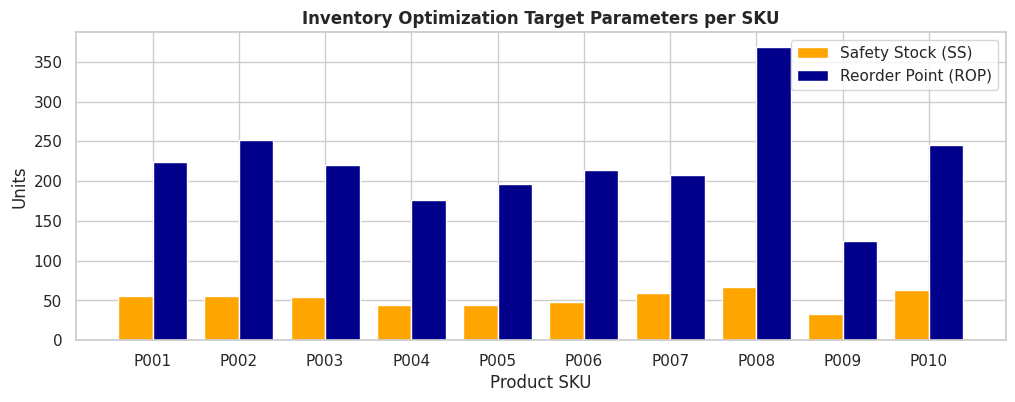

,Product_ID,Avg_Weekly_Demand,Demand_Std_Dev,Lead_Time_Days,Safety_Stock,Reorder_Point,Current_Stock,Target_Stock,Recommended_Order_Qty,EOQ
0,P001,237.46,39.46,5,55.02,224.64,268,462.10,194.10,792.31
1,P002,196.64,33.57,7,55.39,252.04,203,448.68,245.68,543.32
2,P003,290.51,43.56,4,54.33,220.34,423,510.85,87.85,1004.21
3,P004,154.34,28.70,6,43.85,176.14,169,330.47,161.47,400.48
4,P005,133.32,25.17,8,44.39,196.75,182,330.07,148.07,297.08
5,P006,165.83,29.19,7,48.16,213.98,187,379.81,192.81,312.30
6,P007,346.45,55.28,3,59.72,208.20,666,554.65,0.00,843.18
7,P008,211.00,34.13,10,67.31,368.73,249,579.73,330.73,300.45
8,P009,107.72,21.50,6,32.84,125.17,135,232.90,97.90,192.08
9,P010,255.93,44.96,5,62.70,245.51,301,501.44,200.44,448.23


In [22]:
#STEP 8 - Inventory Optimization (SS, ROP, Target Stock, EOQ)
#Translates demand forecasts into operational buffers (SS, ROP, EOQ).
inventory_summary = []
for pid in fe_df["Product_ID"].unique():
    p_data = fe_df[fe_df["Product_ID"] == pid]

    mean_d = p_data["Quantity_Sold"].mean()
    std_d = p_data["Quantity_Sold"].std()
    lt_days = p_data["Lead_Time_Days"].iloc[-1]
    lt_weeks = lt_days / 7.0
    curr_stock = p_data["Stock_Available"].iloc[-1]
    unit_p = p_data["Unit_Price"].iloc[-1]

    # 95% Service Level Factor Z = 1.65
    safety_stock = 1.65 * std_d * np.sqrt(lt_weeks)
    rop = (mean_d * lt_weeks) + safety_stock
    target_stock = rop + mean_d
    rec_order_qty = max(0, target_stock - curr_stock)

    # EOQ
    annual_demand = mean_d * 52
    eoq = np.sqrt((2 * annual_demand * 100) / (0.20 * unit_p))

    inventory_summary.append({
        "Product_ID": pid,
        "Avg_Weekly_Demand": round(mean_d, 2),
        "Demand_Std_Dev": round(std_d, 2),
        "Lead_Time_Days": lt_days,
        "Safety_Stock": round(safety_stock, 2),
        "Reorder_Point": round(rop, 2),
        "Current_Stock": curr_stock,
        "Target_Stock": round(target_stock, 2),
        "Recommended_Order_Qty": round(rec_order_qty, 2),
        "EOQ": round(eoq, 2)
    })

df_inventory = pd.DataFrame(inventory_summary)
df_inventory.to_csv("/content/step12_inventory_optimization.csv", index=False)

# Visualize Inventory Buffers
plt.figure(figsize=(12, 4))
p_indices = np.arange(len(df_inventory))
plt.bar(p_indices - 0.2, df_inventory["Safety_Stock"], width=0.4, label="Safety Stock (SS)", color="orange")
plt.bar(p_indices + 0.2, df_inventory["Reorder_Point"], width=0.4, label="Reorder Point (ROP)", color="darkblue")
plt.xticks(p_indices, df_inventory["Product_ID"])
plt.title("Inventory Optimization Target Parameters per SKU", fontsize=12, fontweight="bold")
plt.xlabel("Product SKU")
plt.ylabel("Units")
plt.legend()
plt.show()

display(df_inventory)


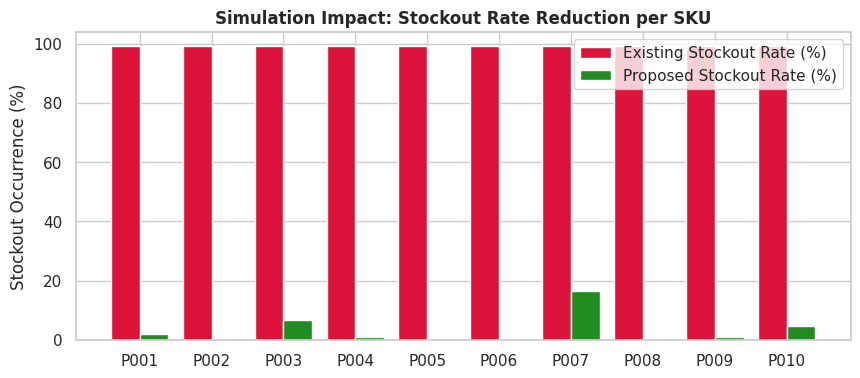

,Product_ID,Existing_Stockout_Rate (%),Proposed_Stockout_Rate (%)
0,P001,99.04,1.92
1,P002,99.04,0.00
2,P003,99.04,6.73
3,P004,99.04,0.96
4,P005,99.04,0.00
5,P006,99.04,0.00
6,P007,99.04,16.35
7,P008,99.04,0.00
8,P009,99.04,0.96
9,P010,99.04,4.81


In [23]:
#STEP 9 -Before-and-After Policy Simulation
#Simulates stockout rates between the baseline static stock strategy vs. the proposed dynamic inventory replenishment policy.

sim_results = []
for pid in fe_df["Product_ID"].unique():
    p_data = fe_df[fe_df["Product_ID"] == pid].sort_values("Date")
    inv_row = df_inventory[df_inventory["Product_ID"] == pid].iloc[0]

    stock_exist = inv_row["Current_Stock"]
    stockouts_exist = 0

    stock_prop = inv_row["Target_Stock"]
    stockouts_prop = 0
    rop = inv_row["Reorder_Point"]
    roq = inv_row["EOQ"]

    for _, row in p_data.iterrows():
        demand = row["Quantity_Sold"]

        # Existing Policy
        if stock_exist < demand:
            stockouts_exist += 1
            stock_exist = 0
        else:
            stock_exist -= demand

        # Proposed Policy
        if stock_prop < demand:
            stockouts_prop += 1
            stock_prop = 0
        else:
            stock_prop -= demand

        if stock_prop <= rop:
            stock_prop += roq

    tot_weeks = len(p_data)
    sim_results.append({
        "Product_ID": pid,
        "Existing_Stockout_Rate (%)": round((stockouts_exist / tot_weeks) * 100, 2),
        "Proposed_Stockout_Rate (%)": round((stockouts_prop / tot_weeks) * 100, 2)
    })

df_sim = pd.DataFrame(sim_results)
df_sim.to_csv("/content/step13_simulation_results.csv", index=False)

# Simulation Comparison Chart
plt.figure(figsize=(10, 4))
p_ind = np.arange(len(df_sim))
plt.bar(p_ind - 0.2, df_sim["Existing_Stockout_Rate (%)"], width=0.4, label="Existing Stockout Rate (%)", color="crimson")
plt.bar(p_ind + 0.2, df_sim["Proposed_Stockout_Rate (%)"], width=0.4, label="Proposed Stockout Rate (%)", color="forestgreen")
plt.xticks(p_ind, df_sim["Product_ID"])
plt.title("Simulation Impact: Stockout Rate Reduction per SKU", fontsize=12, fontweight="bold")
plt.ylabel("Stockout Occurrence (%)")
plt.legend()
plt.show()

display(df_sim)

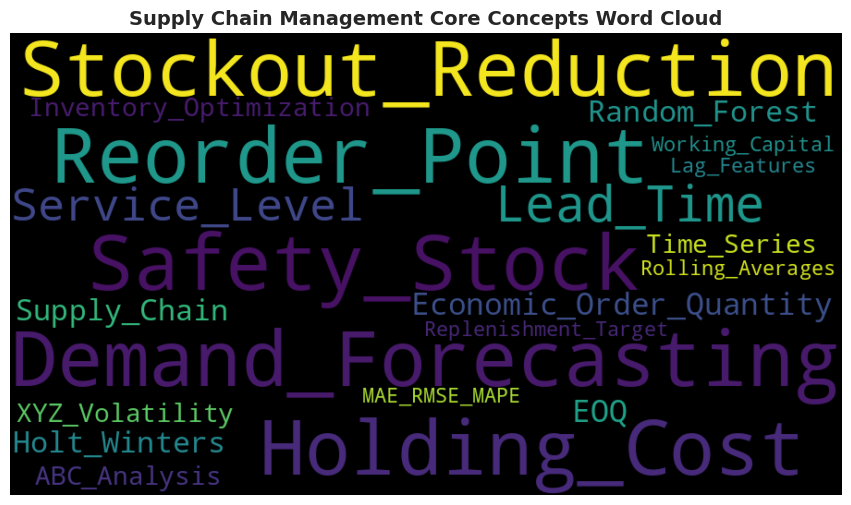

In [25]:
#STEP 10 - Supply Chain Management Word Cloud
from wordcloud import WordCloud

scm_terms = (
    "Demand_Forecasting Safety_Stock Reorder_Point Holding_Cost Stockout_Reduction "
    "Lead_Time Service_Level Economic_Order_Quantity EOQ Random_Forest Holt_Winters "
    "Supply_Chain Inventory_Optimization ABC_Analysis XYZ_Volatility Time_Series "
    "Replenishment_Target MAE_RMSE_MAPE Lag_Features Rolling_Averages Working_Capital"
)

wordcloud = WordCloud(width=900, height=500, background_color="black", colormap="viridis").generate(scm_terms)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Supply Chain Management Core Concepts Word Cloud", fontsize=14, fontweight="bold")
plt.show()